In [1]:
# Impor pustaka yang diperlukan dan nonaktifkan peringatan
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use('Agg') #Gunakan backend Agg untuk matplotlib
import matplotlib.pyplot as plt
plt.switch_backend('Agg') # Pastikan backend benar jika hanya plt yang diimpor
%matplotlib inline

import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Agar hasil dapat direproduksi
np.random.seed(42)

# Cetak pesan singkat sebagai tanda pustaka telah diimpor
print('Pustaka telah diimpor dan backend telah dikonfigurasi')

Pustaka telah diimpor dan backend telah dikonfigurasi


In [2]:
# Muat data dari file csv
file_path = 'dataset/Netflix TV Shows and Movies.csv'
try:
   df = pd.read_csv(file_path, encoding='utf-8')
   print ('Data berhasil dimuat, bentuk:', df.shape)
except Exception as e:
   print('Gagal memuat data:', e)
   #Penanganan eror

Data berhasil dimuat, bentuk: (5283, 11)


In [3]:
# Tinjauan singkat dataset
print('Lima Baris Pertama Data:')
print(df.head())

print ('\nInformas Data:')
print(df.info())

# Periksa nilai yang hilang
print('\nNilai yang Hilang per kolom:')
print(df.isnull().sum())

# Isi nilai numerik yang hilang dengan median (jika ada) dan nilai kategorikal dengan modus
for col in df.columns:
   if df[col].dtype in ['float64', 'int64']:
    if df[col].isnull().sum() > 0:
     df[col].fillna(df[col].median(), inplace=True)
   else:
    if df[col].isnull().sum() > 0:
     df[col].fillna(df[col].mode()[0], inplace=True)

# Terkadang nilai yang hilang atau data yang tidak konsisten bisa merepotkan. Pendekatan menggunakan median dan modus ini membantu menjaga semuanya tetap terkendali.
print('\nNilai yang Hilang setelah Imputasi:')
print(df.isnull().sum())

# Hapus baris duplikat jika ada
df.drop_duplicates(inplace=True)
print('\nBentuk data setelah menghapus duplikat:' , df.shape)

Lima Baris Pertama Data:
   index        id                            title   type  \
0      0   tm84618                      Taxi Driver  MOVIE   
1      1  tm127384  Monty Python and the Holy Grail  MOVIE   
2      2   tm70993                    Life of Brian  MOVIE   
3      3  tm190788                     The Exorcist  MOVIE   
4      4   ts22164     Monty Python's Flying Circus   SHOW   

                                         description  release_year  \
0  A mentally unstable Vietnam War veteran works ...          1976   
1  King Arthur, accompanied by his squire, recrui...          1975   
2  Brian Cohen is an average young Jewish man, bu...          1979   
3  12-year-old Regan MacNeil begins to adapt an e...          1973   
4  A British sketch comedy series with the shows ...          1969   

  age_certification  runtime    imdb_id  imdb_score  imdb_votes  
0                 R      113  tt0075314         8.3    795222.0  
1                PG       91  tt0071853         8

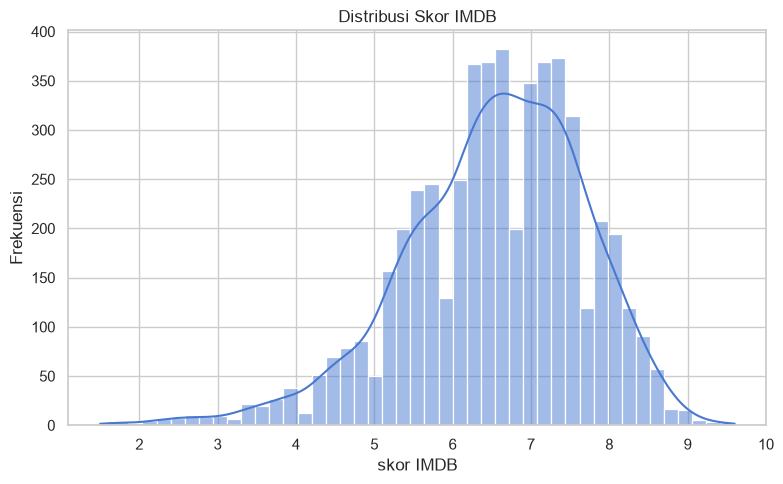

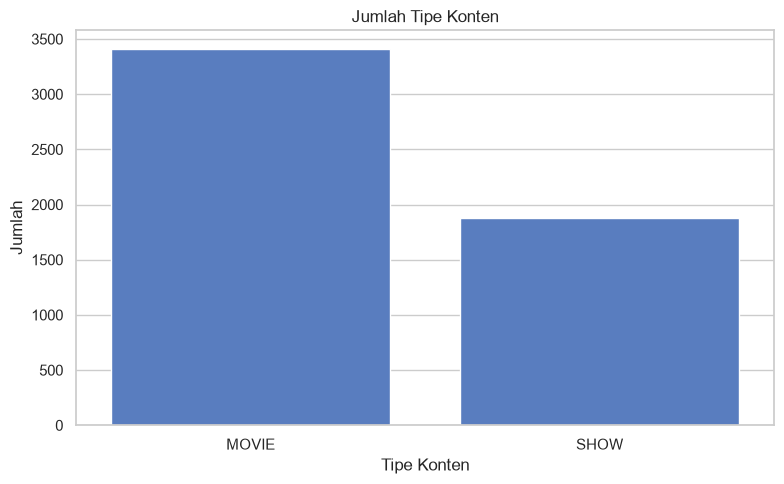

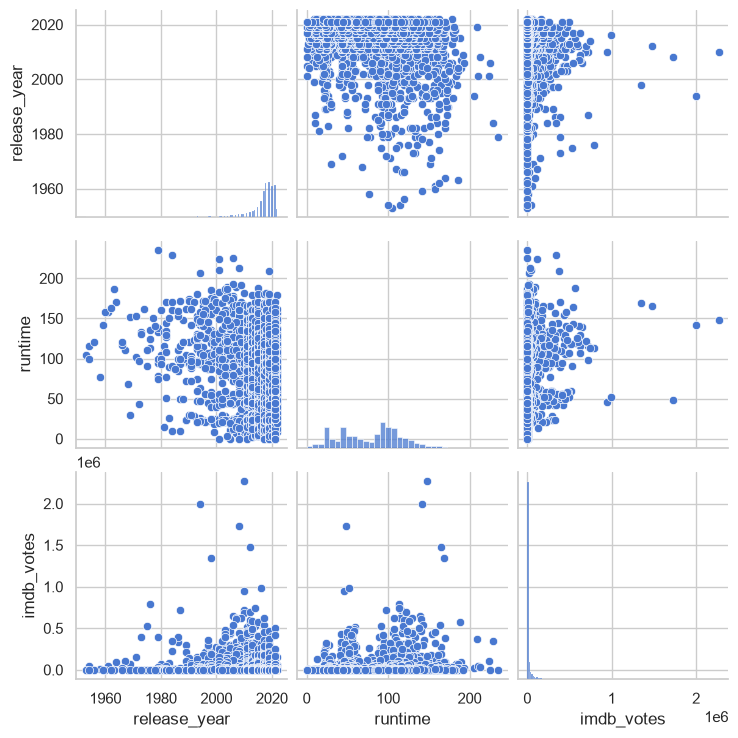

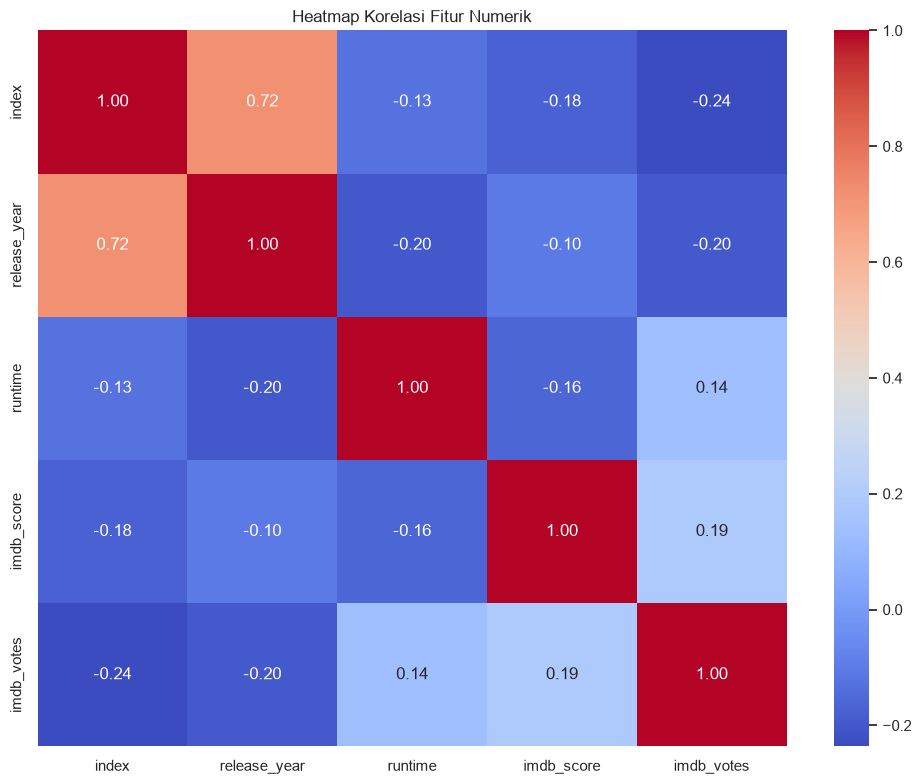

In [ ]:
# Atur gaya visual
sns.set(style='whitegrid', palette='muted')

# Histogram untuk Skor IMDB
plt.figure(figsize=(8,5))
sns.histplot(df['imdb_score'], kde=True)
plt.title('Distribusi Skor IMDB')
plt.xlabel('skor IMDB')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# Count plot untuk tipe konten: Film vs Serial TV
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='type', order=df['type'].value_counts().index)
plt.title('Jumlah Tipe Konten')
plt.xlabel('Tipe Konten')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

# pair plot untuk fitur numerik terpilih
numeric_features = ['release_year', 'runtime', 'imdb_votes']
sns.pairplot(df[numeric_features])
plt.show()

#Heatmap korelasi
numeric_df = df.select_dtypes(include=[np.number])
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(10,8))
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Heatmap Korelasi Fitur Numerik')
    plt.tight_layout()
    plt.show()
else:
    print('Kolom numerik tidak cukup untuk membuat heatmap korelasi.')

In [ ]:
# Tentukan himpunan fitur dana variabel terget
#features = ['release_year', 'runtime', 'imdb_votes']
df = df.dropna(subset=['release_year', 'runtime', 'imdb_votes', 'imdb_score'])
#target = 'imdb_score'

# Siapkan X dan Y
X = df[features]
y = df[target]
target = 'imdb_score'

# Bagi menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inisialisasi dan latih model Regresi Linear
model = LinearRegression()
model.fit(X_train, y_train)

# Prediksi pada data uji
y_pred = model.predict(X_test)

# Evaluasi performa model menggunakan skor R2
r2 = r2_score(y_test, y_pred)
print('Skor R2: ', r2)

# Scatter plot Skor IMDB Aktual vs Prediksi
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel('Skor IMDB Aktual')
plt.ylabel('Skor IMDB Prediksi')
plt.title('Skor IMDB Aktual VS Prediksi')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.tight_layout()
plt.show()

#Gunakan koefisien sebagai pendekatan sederhana untuk tingkat kepentingan fitur
importance = pd.Series(model.coef_, index=features).sort_values()

plt.figure(figsize=(8,5))
importance.plot(kind='barh')
plt.title('Kepentingan Fitur Berdasarkan Koefisien')
plt.xlabel('Nilai Koefisien')
plt.tight_layout()
plt.show()

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values